# 04. 기본 모델·하이퍼파라미터 실험

- 입력: `data/processed/X_*.csv`, `y_*.csv` (03에서 저장)
- 하는 일: 기본 모델(Dense 64-32-1) 학습 → 실험 1~4 (layer/뉴런 수, 활성화 함수, learning rate, 타깃 로그 변환)
  - 한 번에 하나씩만 바꾸고, validation MSE가 가장 낮은 값을 다음 실험에 사용
  - **test 데이터는 사용하지 않음**
- 출력: `results/experiments.csv` (실험 결과 표), `results/best_config.json` (최적 조합) → 05에서 사용

In [1]:
import sys
from pathlib import Path

# 프로젝트 루트(notebooks/의 상위 폴더)를 import 경로에 추가해서 src 패키지를 사용
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import json

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import SEED, RESULTS_DIR, EXPERIMENTS_PATH, BEST_CONFIG_PATH
from src.data import load_splits
from src.model import build_model, plot_history

# 이 노트북에서는 test 데이터(X_test_np, y_test_np)를 사용하지 않음
X_train_np, X_val_np, X_test_np, y_train_np, y_val_np, y_test_np = load_splits()
print(X_train_np.shape, X_val_np.shape)

(5925, 17) (1270, 17)


## 기본 모델

In [2]:
import keras

# random, numpy, tensorflow 시드를 한 번에 고정
keras.utils.set_random_seed(SEED)

model = keras.Sequential([
    keras.Input(shape=(X_train_np.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1),  # 회귀: 출력 뉴런 1개, 활성화 함수 없음
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# test 데이터는 사용하지 않고 validation으로만 확인
history = model.fit(
    X_train_np, y_train_np,
    validation_data=(X_val_np, y_val_np),
    epochs=100,
    batch_size=32,
    verbose=0,
)

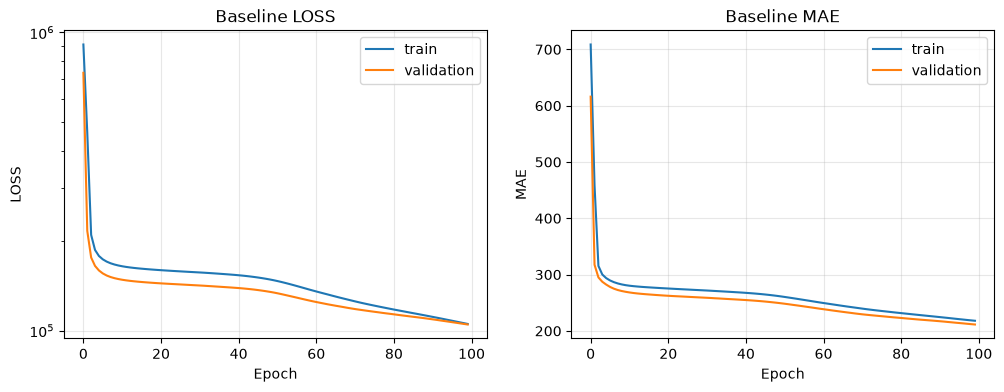

In [4]:
# 학습 곡선
plot_history(history, 'Baseline')

In [5]:
val_mse, val_mae = model.evaluate(X_val_np, y_val_np, verbose=0)
print(f'validation MSE : {val_mse:,.1f}')
print(f'validation RMSE: {np.sqrt(val_mse):,.1f}')
print(f'validation MAE : {val_mae:,.1f}')

validation MSE : 104,863.9
validation RMSE: 323.8
validation MAE : 211.4


## 하이퍼파라미터 실험

기본 모델에서 한 번에 하나씩만 바꾸고, 각 실험에서 validation MSE가 가장 낮은 값을 다음 실험에 사용 (test 데이터 사용 안 함)

In [6]:
n_inputs = X_train_np.shape[1]
BASE = {'hidden_units': (64, 32), 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 100}
results = []    # 모든 실험 결과
histories = {}  # 학습 곡선용

def run_experiment(experiment, param, values, base):
    """base에서 param 하나만 values로 바꿔가며 학습하고, validation MSE가 가장 낮은 값을 반환"""
    rows = []
    for value in values:
        config = {**base, param: value}
        model = build_model(n_inputs, config['hidden_units'], config['activation'], config['learning_rate'])
        history = model.fit(X_train_np, y_train_np, validation_data=(X_val_np, y_val_np),
                            epochs=config['epochs'], batch_size=config['batch_size'], verbose=0)
        val_mse, val_mae = model.evaluate(X_val_np, y_val_np, verbose=0)
        rows.append({'experiment': experiment, 'param': param, 'value': str(value),
                     'val_MSE': val_mse, 'val_RMSE': np.sqrt(val_mse), 'val_MAE': val_mae,
                     'params': model.count_params()})
        histories[(experiment, str(value))] = history.history
    results.extend(rows)
    table = pd.DataFrame(rows)
    best = values[table['val_MSE'].idxmin()]
    return table, best

def plot_experiment(experiment, values):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for value in values:
        h = histories[(experiment, str(value))]
        axes[0].plot(h['val_loss'], label=str(value))
        axes[1].plot(h['val_mae'], label=str(value))
    axes[0].set_yscale('log')
    for ax, name in zip(axes, ['validation MSE', 'validation MAE']):
        ax.set_xlabel('Epoch')
        ax.set_ylabel(name)
        ax.set_title(f'{experiment}: {name}')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.show()

### 실험 1: layer 수 / 뉴런 수

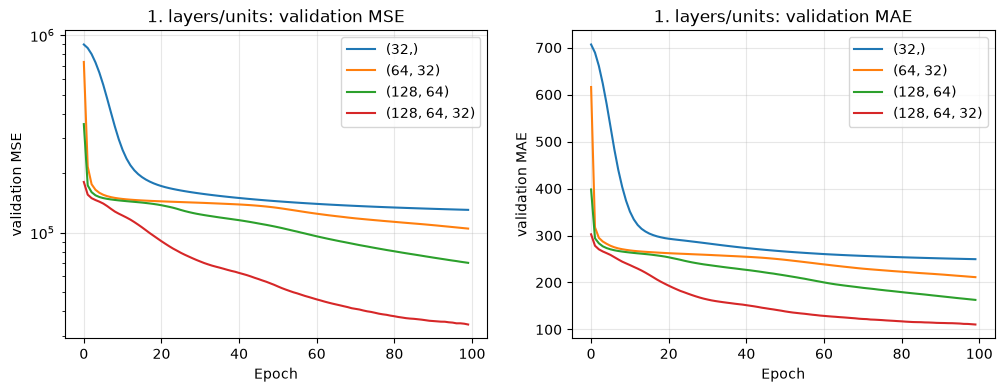

선택: (128, 64, 32)


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params
0,1. layers/units,hidden_units,"(32,)",130440.8,361.2,249.6,609
1,1. layers/units,hidden_units,"(64, 32)",104863.9,323.8,211.4,3265
2,1. layers/units,hidden_units,"(128, 64)",70330.4,265.2,162.9,10625
3,1. layers/units,hidden_units,"(128, 64, 32)",34268.3,185.1,110.6,12673


In [7]:
units_values = [(32,), (64, 32), (128, 64), (128, 64, 32)]
exp1, best_units = run_experiment('1. layers/units', 'hidden_units', units_values, BASE)
plot_experiment('1. layers/units', units_values)
print('선택:', best_units)
exp1.round(1)

### 실험 2: 활성화 함수

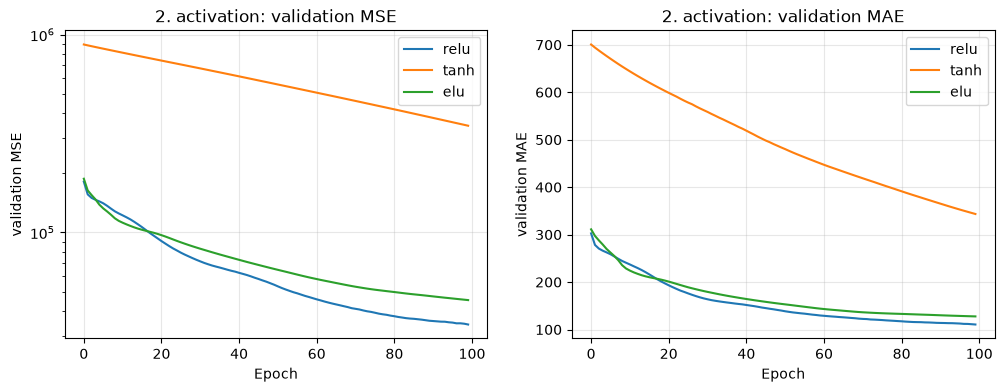

선택: relu


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params
0,2. activation,activation,relu,34268.3,185.1,110.6,12673
1,2. activation,activation,tanh,346296.5,588.5,343.5,12673
2,2. activation,activation,elu,45520.8,213.4,127.6,12673


In [8]:
config2 = {**BASE, 'hidden_units': best_units}
activation_values = ['relu', 'tanh', 'elu']
exp2, best_activation = run_experiment('2. activation', 'activation', activation_values, config2)
plot_experiment('2. activation', activation_values)
print('선택:', best_activation)
exp2.round(1)

### 실험 3: learning rate

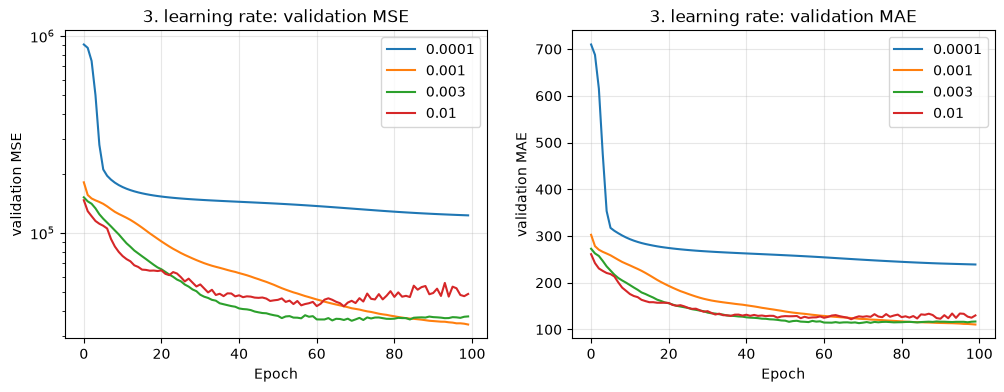

선택: 0.001


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params
0,3. learning rate,learning_rate,0.0001,122722.8,350.3,239.0,12673
1,3. learning rate,learning_rate,0.001,34268.3,185.1,110.6,12673
2,3. learning rate,learning_rate,0.003,37658.2,194.1,117.0,12673
3,3. learning rate,learning_rate,0.01,48970.7,221.3,130.0,12673


In [9]:
config3 = {**config2, 'activation': best_activation}
lr_values = [0.0001, 0.001, 0.003, 0.01]
exp3, best_lr = run_experiment('3. learning rate', 'learning_rate', lr_values, config3)
plot_experiment('3. learning rate', lr_values)
print('선택:', best_lr)
exp3.round(1)

In [10]:
# 전체 실험 결과 요약
best_config = {**config3, 'learning_rate': best_lr}
print('현재까지 최적 조합:', best_config)
pd.DataFrame(results).round(1)

현재까지 최적 조합: {'hidden_units': (128, 64, 32), 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 100}


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params
0,1. layers/units,hidden_units,"(32,)",130440.8,361.2,249.6,609
1,1. layers/units,hidden_units,"(64, 32)",104863.9,323.8,211.4,3265
2,1. layers/units,hidden_units,"(128, 64)",70330.4,265.2,162.9,10625
3,1. layers/units,hidden_units,"(128, 64, 32)",34268.3,185.1,110.6,12673
4,2. activation,activation,relu,34268.3,185.1,110.6,12673
5,2. activation,activation,tanh,346296.5,588.5,343.5,12673
6,2. activation,activation,elu,45520.8,213.4,127.6,12673
7,3. learning rate,learning_rate,0.0001,122722.8,350.3,239.0,12673
8,3. learning rate,learning_rate,0.001,34268.3,185.1,110.6,12673
9,3. learning rate,learning_rate,0.003,37658.2,194.1,117.0,12673


### 실험 4: 타깃 로그 변환

타깃을 `log1p`로 변환해 학습하고, 예측값을 `expm1`로 되돌려 원래 단위(대여 대수)에서 비교

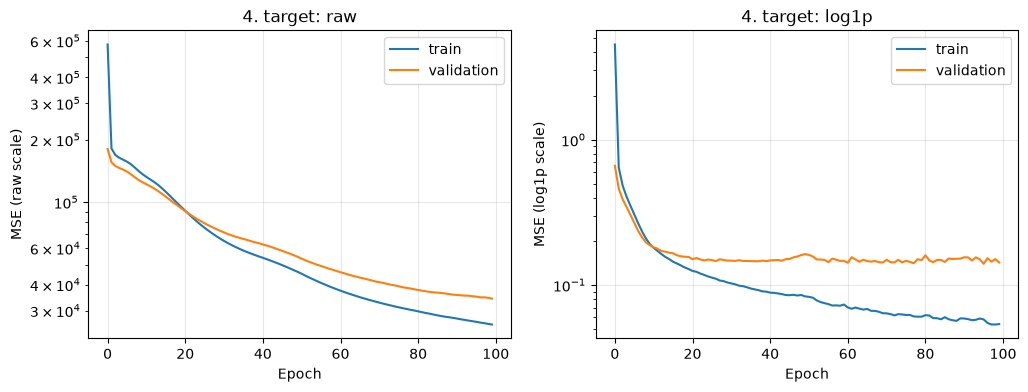

선택: raw


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params,negative_preds
0,4. target,target,raw,34268.3,185.1,110.6,12673,0
1,4. target,target,log1p,58657.4,242.2,141.0,12673,0


In [11]:
config4 = best_config
target_values = ['raw', 'log1p']
rows = []
for target in target_values:
    model = build_model(n_inputs, config4['hidden_units'], config4['activation'], config4['learning_rate'])
    use_log = target == 'log1p'
    y_fit = np.log1p(y_train_np) if use_log else y_train_np
    y_val_fit = np.log1p(y_val_np) if use_log else y_val_np
    history = model.fit(X_train_np, y_fit, validation_data=(X_val_np, y_val_fit),
                        epochs=config4['epochs'], batch_size=config4['batch_size'], verbose=0)
    histories[('4. target', target)] = history.history

    pred = model.predict(X_val_np, verbose=0).ravel()
    if use_log:
        pred = np.expm1(pred)
    val_mse = float(np.mean((pred - y_val_np) ** 2))
    rows.append({'experiment': '4. target', 'param': 'target', 'value': target,
                 'val_MSE': val_mse, 'val_RMSE': np.sqrt(val_mse), 'val_MAE': float(np.mean(np.abs(pred - y_val_np))),
                 'params': model.count_params(), 'negative_preds': int((pred < 0).sum())})
results.extend(rows)
exp4 = pd.DataFrame(rows)
best_target = target_values[exp4['val_MSE'].idxmin()]

# 학습 곡선 (loss 단위가 다르므로 각각 그림)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, target_values):
    h = histories[('4. target', target)]
    ax.plot(h['loss'], label='train')
    ax.plot(h['val_loss'], label='validation')
    ax.set_yscale('log')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(f'MSE ({target} scale)')
    ax.set_title(f'4. target: {target}')
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()
print('선택:', best_target)
exp4.round(1)

In [12]:
# 전체 실험 결과 요약 (실험 1~4)
best_config = {**config4, 'target': best_target}
print('최적 조합:', best_config)

# 실험 결과와 최적 조합 저장 (05에서 사용)
RESULTS_DIR.mkdir(exist_ok=True)
pd.DataFrame(results).to_csv(EXPERIMENTS_PATH, index=False)
with open(BEST_CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(best_config, f, indent=2)
pd.DataFrame(results).drop(columns='negative_preds').round(1)

최적 조합: {'hidden_units': (128, 64, 32), 'activation': 'relu', 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 100, 'target': 'raw'}


,experiment,param,value,val_MSE,val_RMSE,val_MAE,params
0,1. layers/units,hidden_units,"(32,)",130440.8,361.2,249.6,609
1,1. layers/units,hidden_units,"(64, 32)",104863.9,323.8,211.4,3265
2,1. layers/units,hidden_units,"(128, 64)",70330.4,265.2,162.9,10625
3,1. layers/units,hidden_units,"(128, 64, 32)",34268.3,185.1,110.6,12673
4,2. activation,activation,relu,34268.3,185.1,110.6,12673
5,2. activation,activation,tanh,346296.5,588.5,343.5,12673
6,2. activation,activation,elu,45520.8,213.4,127.6,12673
7,3. learning rate,learning_rate,0.0001,122722.8,350.3,239.0,12673
8,3. learning rate,learning_rate,0.001,34268.3,185.1,110.6,12673
9,3. learning rate,learning_rate,0.003,37658.2,194.1,117.0,12673
